# Pipeline demo: `BALT`

**Goal:** run the engine on one observed book from `data/sheets/`.

**BALT** (Innovator Defined Wealth Shield) is a live buffer-style book (not 0DTE).

1. Load sheets → keep BALT legs
2. Payoff at outcome date
3. Dollar Greeks (ETF vs MM side)
4. Spot ladder + gamma flip
5. Time × spot heatmap

In [10]:
import sys
from pathlib import Path

HERE = Path.cwd()
ROOT = HERE.parent if HERE.name == "examples" else HERE
if not (ROOT / "data" / "sheets" / "ETF_List.csv").exists():
    cand = Path("..").resolve()
    if (cand / "data" / "sheets" / "ETF_List.csv").exists():
        ROOT = cand

sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "examples"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from core import pipeline, price_book, aggregate, spot_ladder, spot_time_grid, gamma_flip
import _plot_style as ps

ps.setup()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}" if abs(x) < 10 else f"{x:,.0f}")
pd.set_option("display.width", 160)
print("ROOT =", ROOT)
print("sheets =", ROOT / "data" / "sheets")

ROOT = /Users/orangeao/OrangeAo/StudyMaterials/Columbia/CBS/Derivatives.M.Zurack/Assignments/OptionEmbededEFTs
sheets = /Users/orangeao/OrangeAo/StudyMaterials/Columbia/CBS/Derivatives.M.Zurack/Assignments/OptionEmbededEFTs/data/sheets


## 1 · Load `data/sheets/` and keep BALT

In [11]:
book_all, coverage, etfs, mkt = pipeline.build_from_sheets(ROOT / "data" / "sheets")
book = book_all[book_all["fund"] == "BALT US Equity"].copy()
aum = float(etfs.loc[etfs["fund"] == "BALT US Equity", "aum_usd"].iloc[0])
S0 = mkt.spots["SPY"]
expiry = book["expiry"].iloc[0].date()
print(f"Valuation {mkt.valuation_date} | SPY {S0} | expiry {expiry} | AUM {aum/1e9:.2f}bn | legs {len(book)}")
book[["holding_id", "position", "units", "underlying", "expiry", "cp", "strike", "iv"]]

Valuation 2026-11-20 | SPY 689.81 | expiry 2026-12-31 | AUM 3.29bn | legs 4


,holding_id,position,units,underlying,expiry,cp,strike,iv
120,BBG025KVD0R1 Equity,"-43,502",contracts,SPY,2026-12-31,C,781,NaN
121,BBG025KVD0Y3 Equity,"-43,502",contracts,SPY,2026-12-31,P,610,NaN
122,BBG025KVCTY1 Equity,"43,502",contracts,SPY,2026-12-31,C,1.9100,NaN
123,BBG025KVCV30 Equity,"43,502",contracts,SPY,2026-12-31,P,763,NaN


## 2 · Payoff at outcome date
Deep-ITM call ≈ synthetic long SPY; put spread = buffer; short call = cap.

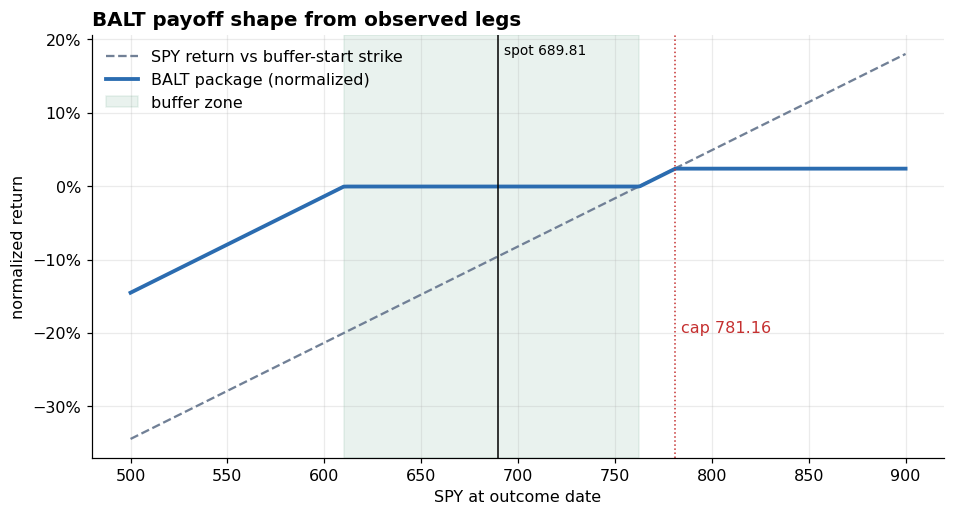

In [12]:
s_grid = np.linspace(500, 900, 401)
# Unit payoff uses sign(position); sizes cancel in the normalized plot.
unit = book.assign(n=np.sign(book["position"]))
payoff = sum(
    r.n * (np.maximum(s_grid - r.strike, 0) if r.cp == "C" else np.maximum(r.strike - s_grid, 0))
    for r in unit.itertuples()
)

# Strikes from the book (buffer start ≈ long put near spot, buffer end = short put, cap = short call)
puts = book.loc[book["cp"] == "P"].sort_values("strike")
calls = book.loc[book["cp"] == "C"].sort_values("strike")
ref = float(puts["strike"].iloc[-1])          # higher put ≈ buffer start
b_end = float(puts["strike"].iloc[0])         # lower put ≈ buffer end
cap = float(calls.loc[calls["strike"] > 50, "strike"].iloc[0])

fig, ax = plt.subplots()
ax.plot(s_grid, s_grid / ref - 1, color=ps.COLORS["grey"], ls="--", label="SPY return vs buffer-start strike")
norm = payoff[np.searchsorted(s_grid, ref)]
ax.plot(s_grid, payoff / norm - 1, color=ps.COLORS["accent"], lw=2.5, label="BALT package (normalized)")
ax.axvspan(b_end, ref, color=ps.COLORS["pos"], alpha=0.10, label="buffer zone")
ax.axvline(cap, color=ps.COLORS["neg"], lw=1, ls=":")
ax.text(cap + 3, -0.20, f"cap {cap:g}", color=ps.COLORS["neg"])
ax.axvline(S0, color="black", lw=1)
ax.text(S0 + 3, 0.18, f"spot {S0:g}", fontsize=9)
ps.pct(ax, "y")
ax.set_xlabel("SPY at outcome date")
ax.set_ylabel("normalized return")
ax.set_title("BALT payoff shape from observed legs")
ax.legend(loc="upper left")
plt.show()

## 3 · Greeks today (ETF side and MM = −ETF)

In [13]:
priced = price_book(book, mkt)
cols = [
    "holding_id", "contracts", "strike", "dte", "iv_used", "delta", "gamma",
    "dollar_delta", "dollar_gamma_1pct", "dollar_vega_1vol",
    "mm_dollar_gamma_1pct", "mm_dollar_vega_1vol",
]
priced[cols]

,holding_id,contracts,strike,dte,iv_used,delta,gamma,dollar_delta,dollar_gamma_1pct,dollar_vega_1vol,mm_dollar_gamma_1pct,mm_dollar_vega_1vol
120,BBG025KVD0R1 Equity,"-43,502",781,41,0.2000,0.0381,0.0018,"-114,201,866","-37,036,731","-832,058","37,036,731","832,058"
121,BBG025KVD0Y3 Equity,"-43,502",610,41,0.2000,-0.0278,0.0014,"83,334,664","-28,561,119","-641,647","28,561,119","641,647"
122,BBG025KVCTY1 Equity,"43,502",1.9100,41,0.2000,0.9988,0.0000,"2,997,121,723",0.0000,0.0000,-0.0000,-0.0000
123,BBG025KVCV30 Equity,"43,502",763,41,0.2000,-0.9203,0.0032,"-2,761,735,711","65,550,249","1,472,636","-65,550,249","-1,472,636"


MM BALT: $Gamma/1% = $47.6k | $Vega/vol = $1.1k | AUM ≈ 3.29bn


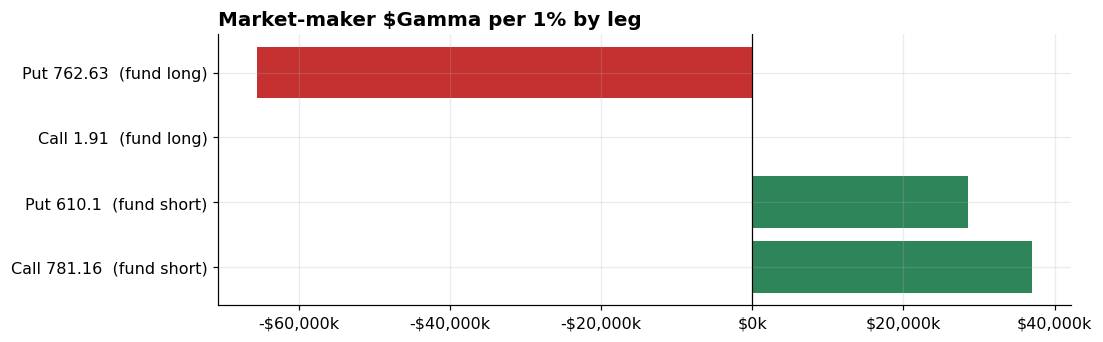

In [14]:
tot = aggregate(priced).iloc[0]
print(
    f"MM BALT: $Gamma/1% = {ps.money(tot.mm_dollar_gamma_1pct)} | "
    f"$Vega/vol = {ps.money(tot.mm_dollar_vega_1vol)} | AUM ≈ {aum/1e9:.2f}bn"
)

fig, ax = plt.subplots(figsize=(10, 3.2))
lbl = (
    priced["cp"].map({"C": "Call", "P": "Put"})
    + " "
    + priced["strike"].map("{:g}".format)
    + np.where(priced["position"] > 0, "  (fund long)", "  (fund short)")
)
v = priced["mm_dollar_gamma_1pct"]
ax.barh(lbl, v, color=np.where(v.to_numpy() >= 0, ps.COLORS["pos"], ps.COLORS["neg"]))
ax.axvline(0, color="black", lw=0.8)
ps.usd(ax, "x", 1e3, "k")
ax.set_title("Market-maker $Gamma per 1% by leg")
plt.show()

## 4 · Spot ladder
Reprices the book at SPY × (1 + shock). Positive MM gamma ⇒ street dampens moves.

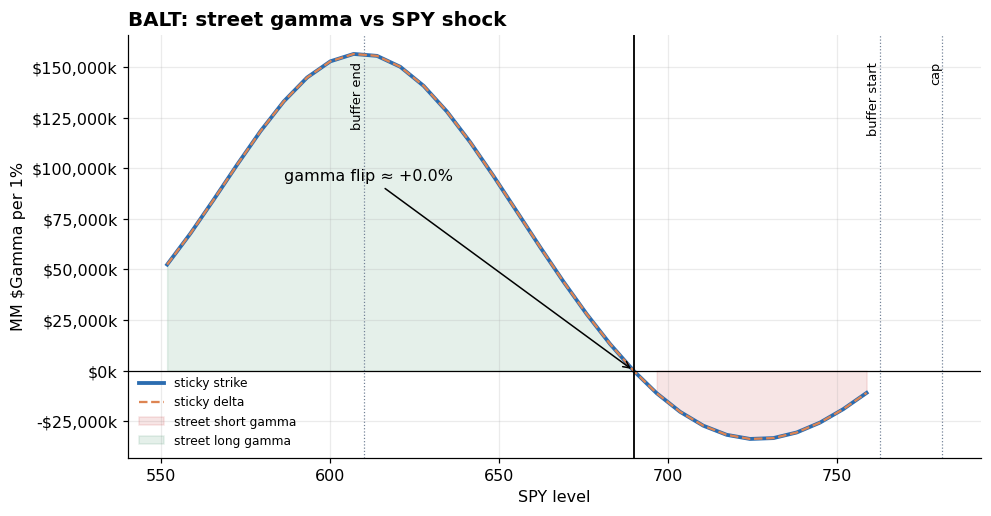

gamma flip: +0.00%


In [15]:
shocks = np.round(np.linspace(-0.20, 0.10, 31), 3)
lad_ss = spot_ladder(book, mkt, shocks, vol_mode="sticky_strike")
lad_sd = spot_ladder(book, mkt, shocks, vol_mode="sticky_delta")
flip = gamma_flip(lad_ss)

fig, ax = plt.subplots()
x = S0 * (1 + lad_ss["shock"])
ax.plot(x, lad_ss["mm_dollar_gamma_1pct"], lw=2.5, color=ps.COLORS["accent"], label="sticky strike")
ax.plot(x, lad_sd["mm_dollar_gamma_1pct"], lw=1.5, ls="--", color=ps.COLORS["inferred"], label="sticky delta")
ax.fill_between(x, 0, lad_ss["mm_dollar_gamma_1pct"], where=lad_ss["mm_dollar_gamma_1pct"] < 0,
                color=ps.COLORS["neg"], alpha=0.12, label="street short gamma")
ax.fill_between(x, 0, lad_ss["mm_dollar_gamma_1pct"], where=lad_ss["mm_dollar_gamma_1pct"] > 0,
                color=ps.COLORS["pos"], alpha=0.12, label="street long gamma")
ax.axhline(0, color="black", lw=0.8)
for level, name in [(ref, "buffer start"), (b_end, "buffer end"), (cap, "cap")]:
    ax.axvline(level, color=ps.COLORS["grey"], lw=0.8, ls=":")
    ax.text(level, ax.get_ylim()[1] * 0.92, name, rotation=90, va="top", ha="right", fontsize=8.5)
if flip is not None:
    ax.axvline(S0 * (1 + flip), color="black", lw=1.2)
    ax.annotate(f"gamma flip ≈ {flip:+.1%}", (S0 * (1 + flip), 0),
                xytext=(S0 * 0.85, float(lad_ss["mm_dollar_gamma_1pct"].max()) * 0.6),
                arrowprops=dict(arrowstyle="->"))
ps.usd(ax, "y", 1e3, "k")
ax.set_xlabel("SPY level")
ax.set_ylabel("MM $Gamma per 1%")
ax.set_title("BALT: street gamma vs SPY shock")
ax.legend(loc="best", fontsize=8)
plt.show()
print("gamma flip:", None if flip is None else f"{flip:+.2%}")

## 5 · Time × spot heatmap

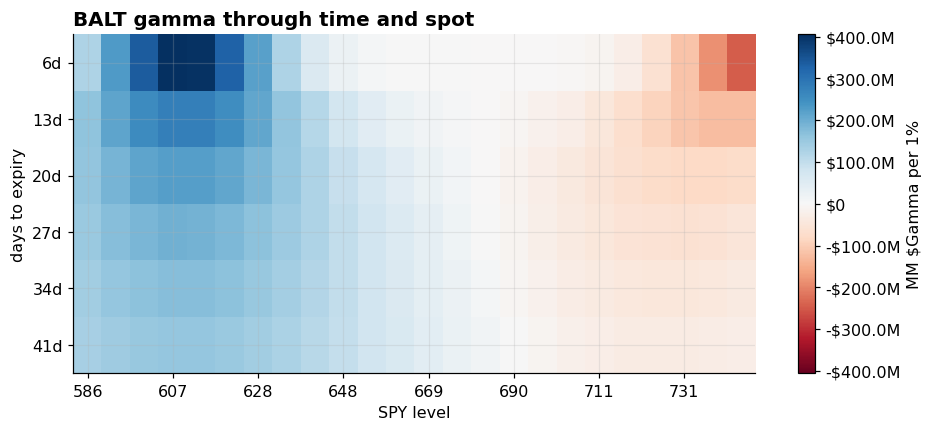

In [16]:
days = [0, 7, 14, 21, 28, 35]
grid = spot_time_grid(book, mkt, shocks=np.round(np.linspace(-0.15, 0.08, 24), 3), days_forward=days)
dte0 = (pd.Timestamp(expiry) - pd.Timestamp(mkt.valuation_date)).days

fig, ax = plt.subplots(figsize=(10, 4))
lim = np.nanmax(np.abs(grid.values)) or 1.0
im = ax.imshow(grid.values, aspect="auto", cmap="RdBu", vmin=-lim, vmax=lim, origin="lower")
ax.set_yticks(range(len(days)), [f"{max(dte0 - d, 0)}d" for d in days])
xt = range(0, grid.shape[1], 3)
ax.set_xticks(list(xt), [f"{S0 * (1 + grid.columns[i]):,.0f}" for i in xt])
ax.set_xlabel("SPY level")
ax.set_ylabel("days to expiry")
cb = fig.colorbar(im, ax=ax, format=mtick.FuncFormatter(lambda x, _: ps.money(x) if x else "$0"))
cb.set_label("MM $Gamma per 1%")
ax.set_title("BALT gamma through time and spot")
plt.show()

## Takeaways

In [17]:
z = lad_ss.set_index("shock")["mm_dollar_gamma_1pct"]
print(f"• Spot {S0:g}: street is {'LONG' if z.loc[0] > 0 else 'SHORT'} {ps.money(abs(z.loc[0]))} gamma per 1%.")
if flip is not None:
    print(f"• Gamma flips at {flip:+.1%} SPY move.")
else:
    print("• No gamma flip inside the plotted shock range.")
j = int(np.argmin(np.abs(z.index.to_numpy() - (-0.10))))
print(f"• Near -10% (shock {z.index[j]:+.1%}): street gamma = {ps.money(z.iloc[j])} per 1%.")
print("• Data source: data/sheets/ only (ETF_List, Option_Book_Copy, Underlying_Market_Copy, holdings/).")

• Spot 689.81: street is LONG $47.6k gamma per 1%.
• Gamma flips at +0.0% SPY move.
• Near -10% (shock -10.0%): street gamma = $150.1M per 1%.
• Data source: data/sheets/ only (ETF_List, Option_Book_Copy, Underlying_Market_Copy, holdings/).
